# Multivariate Regression Model: Student Performace Checker and Early Warning System.
Note: This notebook is explained in detail in README, please review it from there.

Importing required packages

In [10]:
#library to ignore unnecessary warning
import warnings

#libraries for data manipulation and maths calculation
import numpy as np
import pandas as pd

#libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

#scikit-learn preprocessing and pipeline libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

#scikit-learn regression models
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

#library for model serialization
import joblib

#visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

In [11]:
# Loading the dataset
DATA_PATH = "/home/natinaelboda/math_ml_datascienc/data_sets/students_performance_dataset.csv"
df = pd.read_csv(DATA_PATH)

print(f"Initial Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns\n")

# Inspecting missing values
# Here is issue of pandas treating "None" as missing values but
# "None" in Parent_Education_Level column is actual value
# meaning parent do not have official degree, or diploma or others
# so it should be handled
print("Missing values before fixing 'None' string:")
print(df.isnull().sum()[df.isnull().sum() > 0])


# Fixing issue of None: pandas reads the literal category "None" as NaN.
# So "None" should be restored as a valid text category in Parent_Education_Level.
df["Parent_Education_Level"] = df["Parent_Education_Level"].fillna("None")

# Verify there are zero missing values across the entire dataset
print(f"Total missing values remaining after fix: {df.isnull().sum().sum()}")

# Preview the first 5 rows
df.head()

Initial Dataset Shape: 5000 rows and 23 columns

Missing values before fixing 'None' string:
Parent_Education_Level    1025
dtype: int64
Total missing values remaining after fix: 0


,Student_ID,First_Name,Last_Name,Email,Gender,Age,Department,Attendance (%),Midterm_Score,Final_Score,...,Projects_Score,Total_Score,Grade,Study_Hours_per_Week,Extracurricular_Activities,Internet_Access_at_Home,Parent_Education_Level,Family_Income_Level,Stress_Level (1-10),Sleep_Hours_per_Night
0,S1000,Omar,Williams,student0@university.com,Female,22,Mathematics,97.36,40.61,59.61,...,62.84,59.8865,F,10.3,Yes,No,Master's,Medium,1,5.9
1,S1001,Maria,Brown,student1@university.com,Male,18,Business,97.71,57.27,74.00,...,98.23,81.9170,B,27.1,No,No,High School,Low,4,4.3
2,S1002,Ahmed,Jones,student2@university.com,Male,24,Engineering,99.52,41.84,63.85,...,91.22,67.7170,D,12.4,Yes,No,High School,Low,9,6.1
3,S1003,Omar,Williams,student3@university.com,Female,24,Engineering,90.38,45.65,44.44,...,55.48,51.6535,F,25.5,No,Yes,High School,Low,8,4.9
4,S1004,John,Smith,student4@university.com,Female,23,CS,59.41,53.13,61.77,...,87.43,71.4030,C,13.3,Yes,No,Master's,Medium,6,4.5


In [14]:
warnings.filterwarnings("ignore")

# Removing Personally Identifiable Information columns which are just ID columns
# Other than identifying the row(student), they don't have any importance for 
#model training so I'm dropping them immediatly
pii_columns = ["Student_ID", "First_Name", "Last_Name", "Email"]
df_clean = df.drop(columns=pii_columns)

print(f"Shape after removing 4 PII columns: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns\n")

# Separateing and displaying numeric vs. categorical columns to verify dataset richness
numeric_cols = df_clean.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df_clean.select_dtypes(include=["object"]).columns.tolist()

print(f"Numeric Columns ({len(numeric_cols)}): {numeric_cols}\n")
print(f"Categorical Columns ({len(categorical_cols)}): {categorical_cols}")

Shape after removing 4 PII columns: 5000 rows, 19 columns

Numeric Columns (12): ['Age', 'Attendance (%)', 'Midterm_Score', 'Final_Score', 'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score', 'Projects_Score', 'Total_Score', 'Study_Hours_per_Week', 'Stress_Level (1-10)', 'Sleep_Hours_per_Night']

Categorical Columns (7): ['Gender', 'Department', 'Grade', 'Extracurricular_Activities', 'Internet_Access_at_Home', 'Parent_Education_Level', 'Family_Income_Level']


## Data Analysis & Visualizations
Before selecting final features or encoding categorical columns, visualizing the dataset to inspect linear correlations, variable distributions, and socioeconomic group differences.

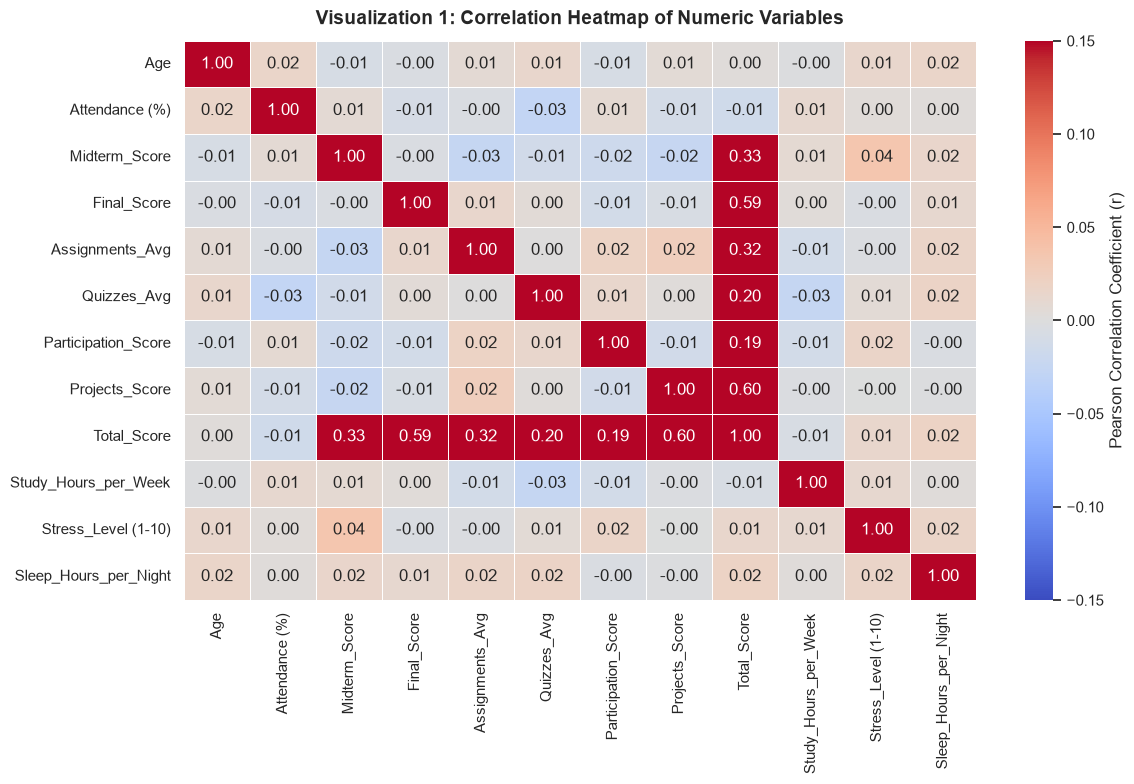

Exact correlation of numeric features with Total_Score:
Projects_Score           0.596076
Final_Score              0.588608
Midterm_Score            0.330636
Assignments_Avg          0.316676
Quizzes_Avg              0.201833
Participation_Score      0.187547
Sleep_Hours_per_Night    0.018847
Stress_Level (1-10)      0.013734
Age                      0.002746
Study_Hours_per_Week    -0.006609
Attendance (%)          -0.014165
Name: Total_Score, dtype: float64


In [18]:
# Calculating the Pearson correlation matrix for all 13 numeric columns
corr_matrix = df_clean[numeric_cols].corr()

# Plot the Correlation Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.15,
    vmax=0.15,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation Coefficient (r)"}
)
plt.title("Visualization 1: Correlation Heatmap of Numeric Variables", fontsize=14, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

# Printing exact correlations with the target variable (Total_Score) sorted by magnitude
print("Exact correlation of numeric features with Total_Score:")
print(corr_matrix["Total_Score"].drop("Total_Score").sort_values(ascending=False))

**What Visualization 1 Shows & Modelling Decision:**
This correlation heatmap displays the linear relationships ($r$) across all 13 numeric columns, including their correlation with target variable, `Total_Score`. From this correlation heatmap, we understand that `Age`, `Stress_Level (1-10)`, `Sleep_Hours_per_Night`, and `Study_Hours_per_Week` have near-zero linear correlation with `Total_Score`, and another thing is `Final_Score` representing result of final exam at the end of semester, can cause data leakage so I decide to drop it as well as (`Midterm_Score`, `Assignments_Avg`, `Projects_Score`, `Quizzes_Avg`, and `Attendance (%)`).

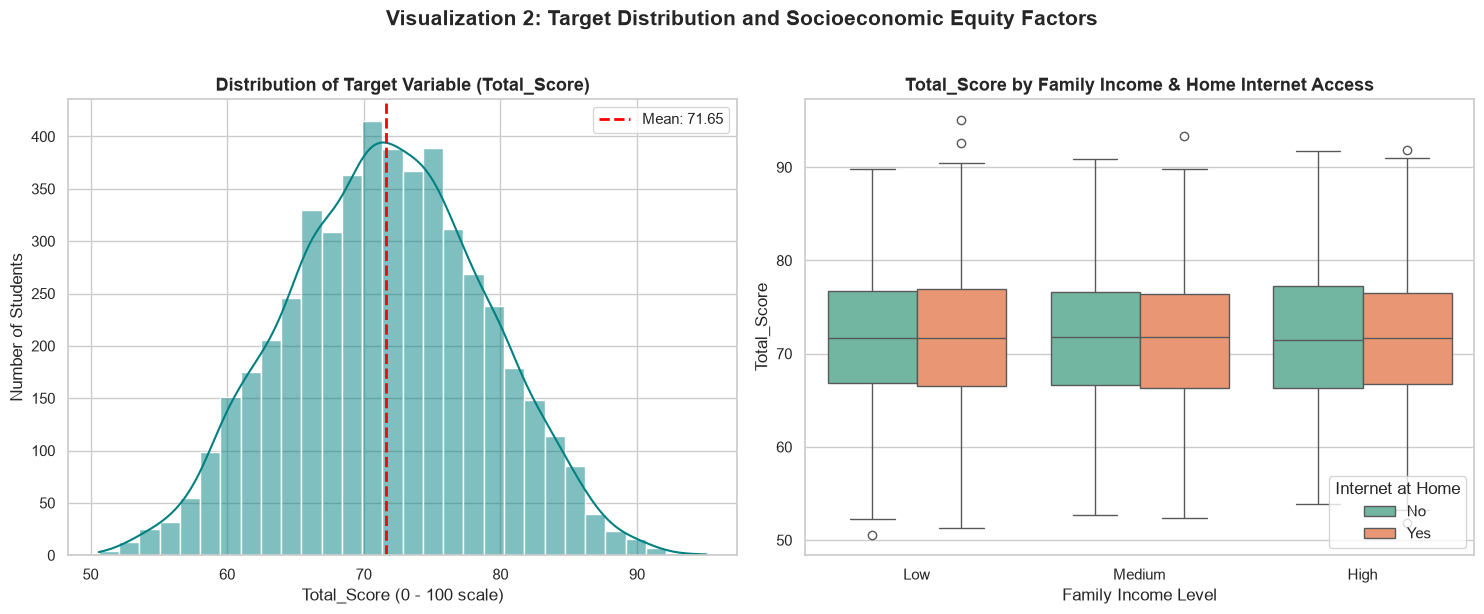

In [16]:
# Histogram of Target and Boxplot of Socioeconomic Categories
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Histogram and KDE of the target variable (Total_Score)
sns.histplot(df_clean["Total_Score"], bins=30, kde=True, color="teal", ax=axes[0])
axes[0].axvline(df_clean["Total_Score"].mean(), color="red", linestyle="--", linewidth=2, label=f"Mean: {df_clean['Total_Score'].mean():.2f}")
axes[0].set_title("Distribution of Target Variable (Total_Score)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Total_Score (0 - 100 scale)")
axes[0].set_ylabel("Number of Students")
axes[0].legend()

# Boxplot of Total_Score across Family Income Level and Internet Access
sns.boxplot(
    data=df_clean,
    x="Family_Income_Level",
    y="Total_Score",
    hue="Internet_Access_at_Home",
    order=["Low", "Medium", "High"],
    palette="Set2",
    ax=axes[1]
)
axes[1].set_title("Total_Score by Family Income & Home Internet Access", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Family Income Level")
axes[1].set_ylabel("Total_Score")
axes[1].legend(title="Internet at Home", loc="lower right")

plt.suptitle("Visualization 2: Target Distribution and Socioeconomic Equity Factors", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**What Visualization 2 Shows & Modelling Decision:**
The histogram on the left shows that `Total_Score` is distributed evenly bewteen minimum score of 50 and maximum score of 100 with its mean 71.65. Boxplot on the right shows how students' `Total_Score` varies across `Family_Income_Level` and `Internet_Access_at_Home`. I retain `Internet_Access_at_Home`, `Family_Income_Level`, and `Parent_Education_Level` as category features and later encode them.

## Feature Engineering: Selecting Features While Dropping unnecessary ones.
To prevent data leakage and make the model be able to efficient and effect for building Student Performance Checker system, and by carefully analysizing the visualization,  I drop the following columns:
1. **Personally Identifiable Information Columns (4 dropped — `Student_ID`, `First_Name`, `Last_Name`, `Email`)**
2. **Target Leakage Columns (2 dropped — `Final_Score`, `Grade`)**
3. **Near zero correlation columns with Target (8 dropped — `Age`, `Gender`, `Department`, `Extracurricular_Activities`, `Study_Hours_per_Week`, `Participation_Score`, `Stress_Level (1-10)`, `Sleep_Hours_per_Night`)**

**Retained Features (8 Total — 5 Numeric + 3 Categorical) & Target (`Total_Score`):**
* **Numeric Features (5):** `Attendance (%)`, `Midterm_Score`, `Assignments_Avg`, `Quizzes_Avg`, `Projects_Score`
* **Categorical Features (3):** `Internet_Access_at_Home`, `Family_Income_Level`, `Parent_Education_Level`
* **Target Variable ($y$):** `Total_Score`